In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

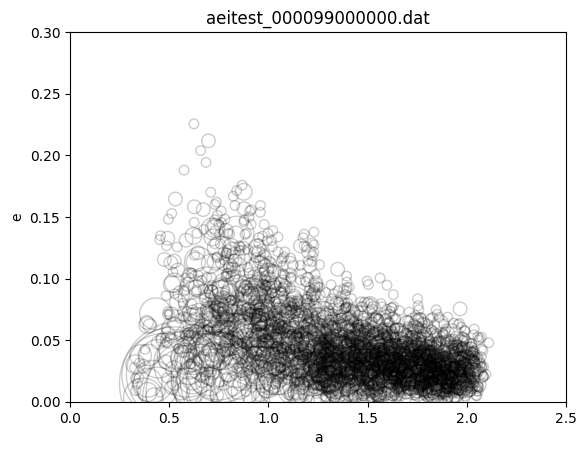

In [4]:
import matplotlib.animation as animation
import os

path = '/Users/honeyeah/Codes/data/genga_output_for_animation'

# Generate the filenames at intervals of 1e7
file_indices = list(range(0, 100000000, 1000000))  # includes 110000000
filenames = [f"aeitest_{i:012d}.dat" for i in file_indices]

# Column names
colnames = ['time', 'i', 'a', 'e', 'inc',
            'Omega', 'w', 'Theta', 'E', 'M', 'm', 'r']

# Set up the figure
fig, ax = plt.subplots()
scat = ax.scatter([], [], s=[], marker='o', facecolors='none', edgecolors='black')

ax.set_xlim(0, 2.5)   # adjust to your expected 'a' range
ax.set_ylim(0, 0.3)   # eccentricity range is [0,1]
ax.set_xlabel("a")
ax.set_ylabel("e")
title = ax.set_title("")

def init():
    scat.set_offsets(np.empty((0, 2)))  # empty (N, 2) array
    scat.set_sizes([])
    return scat,

def update(frame):
    filepath = os.path.join(path, filenames[frame])
    df = pd.read_csv(filepath, sep=r"\s+", names=colnames, header=None)
    
    # Update scatter data
    coords = df[['a', 'e']].values
    sizes = df['m'].values * 5 * 1e10
    alpha = 0.2
    
    scat.set_alpha(alpha)
    scat.set_offsets(coords)
    scat.set_sizes(sizes)
    title.set_text(f"{filenames[frame]}")
    
    return scat, title

ani = animation.FuncAnimation(fig, update, frames=len(filenames),
                              init_func=init, blit=True, interval=500)

ani.save("genga_animation.gif", writer="pillow", fps=5, dpi=150)
plt.show()
